<a href="https://colab.research.google.com/github/lixuwei2005-star/data-profiling-assignment1/blob/main/Assignment_1_Data_Profiling_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1: Data Profiling (EDA) Report

### Group Members

1. **HU XIAOZHANG** - A214111  
2. **CHI YULONG** - A213955  
3. **LI XUWEI** - A214014

## 1. Scenario

This dataset is from the healthcare sector and contains information about patients with diabetes and their hospital encounters. It is suitable for data profiling because it contains missing values, outliers, invalid values, and possible privacy and bias risks. The main questions are where the data quality problems occur, how serious they are, and how they can be handled before further analysis.

## 2. Data Source

The dataset used in this assignment is the diabetic hospital dataset from Kaggle. It contains records of hospital encounters for patients with diabetes in US hospitals (1999-2008).

**Source:** Kaggle
**Dataset:** Diabetes
**File used:** `diabetic_data.csv`
**URL:** https://www.kaggle.com/datasets/brandao/diabetes?select=diabetic_data.csv

The dataset was downloaded manually from Kaggle as a CSV file and uploaded to the Google Colab environment. It was loaded using the pandas `read_csv()` function. The full file contains 101,766 rows and 50 columns.

In [1]:
import pandas as pd

df = pd.read_csv('/content/diabetic_data.csv')

print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Rows and columns: (101766, 50)

Column names:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

First 5 rows:


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 3. Data Profiling and Issue Handling

### 3.1 Missing Values

Missing values were identified by checking both null values and the placeholder `?`, which this dataset uses for unknown values. The count and percentage of missing data were calculated for each affected column. The handling decisions and reasons are explained in the Data Cleaning part of Section 3.4.

Note: `max_glu_serum` and `A1Cresult` contain the value `None`, which pandas reads as missing by default. In this dataset, `None` means the test was **not performed**, not that the data was lost. These two columns are therefore treated differently from truly missing data (see Section 3.4).

In [2]:
missing = df.isna().sum() + (df == '?').sum()

missing_table = pd.DataFrame({
    'Missing Values': missing,
    'Missing Percentage': (missing / len(df) * 100).round(2)
})

missing_table = missing_table[missing_table['Missing Values'] > 0]
missing_table = missing_table.sort_values(
    by='Missing Values',
    ascending=False
)

display(missing_table)

,Missing Values,Missing Percentage
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


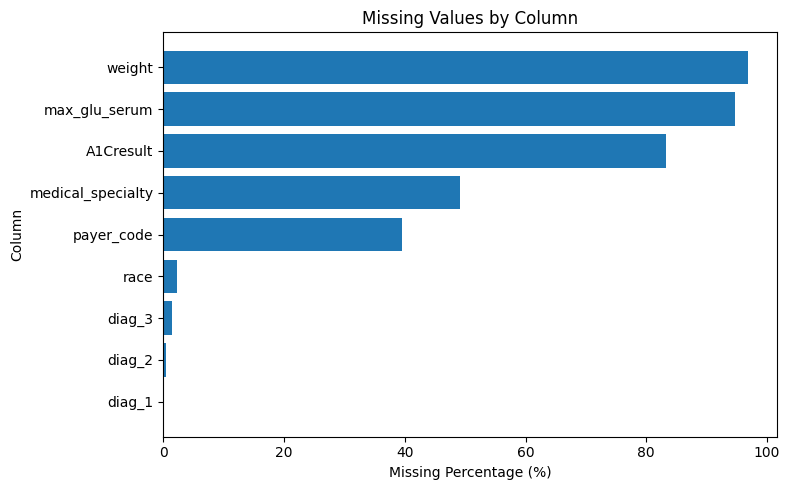

In [3]:
import matplotlib.pyplot as plt

missing_plot = missing_table.sort_values('Missing Percentage')

plt.figure(figsize=(8, 5))
plt.barh(missing_plot.index, missing_plot['Missing Percentage'])
plt.xlabel('Missing Percentage (%)')
plt.ylabel('Column')
plt.title('Missing Values by Column')
plt.tight_layout()
plt.show()

### 3.2 Numerical Descriptive Statistics

Descriptive statistics were calculated for the main numerical variables to understand their distribution and identify unusual values. The results include the count, mean, standard deviation, minimum, maximum, and quartiles.

In [4]:
numeric_data = df[
    ['time_in_hospital',
     'num_lab_procedures',
     'num_procedures',
     'num_medications',
     'number_outpatient',
     'number_emergency',
     'number_inpatient',
     'number_diagnoses']
]

display(numeric_data.describe().T)

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101766.0,7.422607,1.933600,1.0,6.0,8.0,9.0,16.0


### 3.3 Outliers

Outliers were detected using the Interquartile Range (IQR) method. The lower and upper limits were calculated using Q1 and Q3. Values outside these limits were counted as potential outliers.

In [5]:
outlier_summary = []

for column in numeric_data.columns:
    Q1 = numeric_data[column].quantile(0.25)
    Q3 = numeric_data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((numeric_data[column] < lower) |
                (numeric_data[column] > upper)).sum()

    outlier_summary.append([column, Q1, Q3, lower, upper, outliers])

outlier_table = pd.DataFrame(
    outlier_summary,
    columns=['Column', 'Q1', 'Q3', 'Lower Limit', 'Upper Limit', 'Outliers']
)

display(outlier_table)

,Column,Q1,Q3,Lower Limit,Upper Limit,Outliers
0,time_in_hospital,2.0,6.0,-4.0,12.0,2252
1,num_lab_procedures,31.0,57.0,-8.0,96.0,143
2,num_procedures,0.0,2.0,-3.0,5.0,4954
3,num_medications,10.0,20.0,-5.0,35.0,2557
4,number_outpatient,0.0,0.0,0.0,0.0,16739
5,number_emergency,0.0,0.0,0.0,0.0,11383
6,number_inpatient,0.0,1.0,-1.5,2.5,7049
7,number_diagnoses,6.0,9.0,1.5,13.5,281


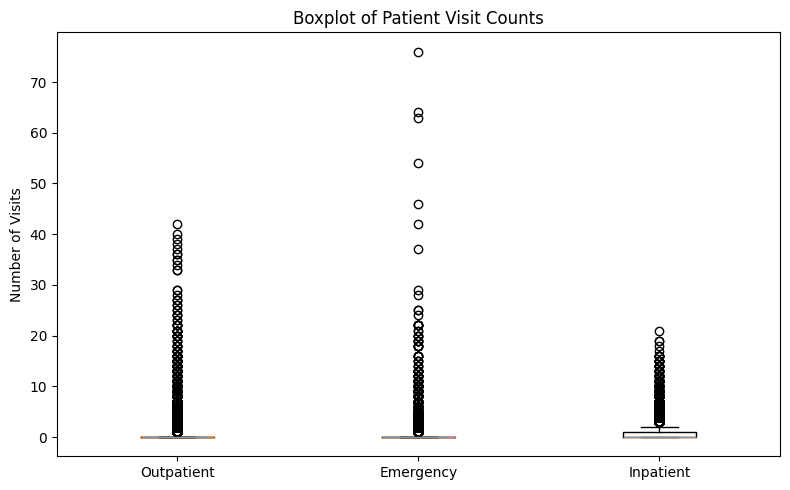

In [6]:
plt.figure(figsize=(8, 5))

plt.boxplot([
    df['number_outpatient'],
    df['number_emergency'],
    df['number_inpatient']
])

plt.xticks(
    [1, 2, 3],
    ['Outpatient', 'Emergency', 'Inpatient']
)

plt.ylabel('Number of Visits')
plt.title('Boxplot of Patient Visit Counts')
plt.tight_layout()
plt.show()

The boxplot shows many potential outliers in the patient visit variables.

For `number_outpatient` and `number_emergency`, Q1 and Q3 are both 0, so the IQR method flags every non-zero value as an outlier. This shows that IQR is not suitable for highly skewed count data where most patients have zero visits.

**Decision: all outliers were kept.** The values in all columns (including `time_in_hospital`, `num_medications` and `num_procedures`) are within clinically plausible ranges. They likely represent real patients with complex conditions or frequent hospital visits rather than data entry errors. Removing or capping them would lose valid information about high-risk patients.

### 3.4 Other Quality Issues

Other data quality issues were checked, including duplicate rows, missing values represented by `?`, invalid values, data types, and cardinality. These checks help identify inconsistent or unsuitable data before further analysis.

In [7]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


#### Data Types

The data types of all columns were checked to identify columns with inappropriate or inconsistent data types.

In [8]:
print(df.dtypes)

encounter_id                 int64
patient_nbr                  int64
race                        object
gender                      object
age                         object
weight                      object
admission_type_id            int64
discharge_disposition_id     int64
admission_source_id          int64
time_in_hospital             int64
payer_code                  object
medical_specialty           object
num_lab_procedures           int64
num_procedures               int64
num_medications              int64
number_outpatient            int64
number_emergency             int64
number_inpatient             int64
diag_1                      object
diag_2                      object
diag_3                      object
number_diagnoses             int64
max_glu_serum               object
A1Cresult                   object
metformin                   object
repaglinide                 object
nateglinide                 object
chlorpropamide              object
glimepiride         

#### Cardinality

The number of unique values in each column was checked to identify columns with very high or very low cardinality.

In [9]:
print("Cardinality of each column:")
print(df.nunique())

Cardinality of each column:
encounter_id                101766
patient_nbr                  71518
race                             6
gender                           3
age                             10
weight                          10
admission_type_id                8
discharge_disposition_id        26
admission_source_id             17
time_in_hospital                14
payer_code                      18
medical_specialty               73
num_lab_procedures             118
num_procedures                   7
num_medications                 75
number_outpatient               39
number_emergency                33
number_inpatient                21
diag_1                         717
diag_2                         749
diag_3                         790
number_diagnoses                16
max_glu_serum                    3
A1Cresult                        3
metformin                        4
repaglinide                      4
nateglinide                      4
chlorpropamide             

The cardinality check shows two issues:

- `patient_nbr` has fewer unique values than the number of rows, which means the same patient can have several hospital encounters. These are not duplicate rows, because each encounter has a different `encounter_id`.
- Some medication columns (e.g. `examide`, `citoglipton`) have only one unique value. These constant columns carry no information and are dropped later.

In [10]:
question_mark_counts = {}

for column in df.columns:
    count = (df[column] == '?').sum()
    if count > 0:
        question_mark_counts[column] = count

print("Columns containing '?' values:")
print(question_mark_counts)

Columns containing '?' values:
{'race': np.int64(2273), 'weight': np.int64(98569), 'payer_code': np.int64(40256), 'medical_specialty': np.int64(49949), 'diag_1': np.int64(21), 'diag_2': np.int64(358), 'diag_3': np.int64(1423)}


In [11]:
special_values = ['?', 'Unknown/Invalid']

for value in special_values:
    print(f"\nValue: {value}")
    for column in df.columns:
        count = (df[column].astype(str) == value).sum()
        if count > 0:
            print(column, ":", count)

print("\nValue: NaN (null)")
null_counts = df.isna().sum()
print(null_counts[null_counts > 0])


Value: ?
race : 2273
weight : 98569
payer_code : 40256
medical_specialty : 49949
diag_1 : 21
diag_2 : 358
diag_3 : 1423

Value: Unknown/Invalid
gender : 3

Value: NaN (null)
max_glu_serum    96420
A1Cresult        84748
dtype: int64


#### Data Cleaning

The placeholder `?` was converted into a proper missing value (`pd.NA`) so that all missing data can be handled consistently. The `Unknown/Invalid` gender value is also an invalid category, so it was treated as missing.

In [12]:
df_clean = df.copy()

df_clean = df_clean.replace('?', pd.NA)

df_clean['gender'] = df_clean['gender'].replace('Unknown/Invalid', pd.NA)

print("Missing values after cleaning:")
print(df_clean.isna().sum().sort_values(ascending=False).head(15))

Missing values after cleaning:
weight                 98569
max_glu_serum          96420
A1Cresult              84748
medical_specialty      49949
payer_code             40256
race                    2273
diag_3                  1423
diag_2                   358
diag_1                    21
gender                     3
time_in_hospital           0
admission_source_id        0
num_lab_procedures         0
encounter_id               0
patient_nbr                0
dtype: int64


Rows with a missing target value (`readmitted`) are checked below. These rows are dropped because the target variable cannot be reliably imputed.

In [13]:
print(df_clean[df_clean['readmitted'].isna()])

Empty DataFrame
Columns: [encounter_id, patient_nbr, race, gender, age, weight, admission_type_id, discharge_disposition_id, admission_source_id, time_in_hospital, payer_code, medical_specialty, num_lab_procedures, num_procedures, num_medications, number_outpatient, number_emergency, number_inpatient, diag_1, diag_2, diag_3, number_diagnoses, max_glu_serum, A1Cresult, metformin, repaglinide, nateglinide, chlorpropamide, glimepiride, acetohexamide, glipizide, glyburide, tolbutamide, pioglitazone, rosiglitazone, acarbose, miglitol, troglitazone, tolazamide, examide, citoglipton, insulin, glyburide-metformin, glipizide-metformin, glimepiride-pioglitazone, metformin-rosiglitazone, metformin-pioglitazone, change, diabetesMed, readmitted]
Index: []

[0 rows x 50 columns]


In [14]:
df_clean = df_clean.dropna(subset=['readmitted']).copy()

print("Original rows:", len(df))
print("Rows after cleaning:", len(df_clean))
print("Removed rows:", len(df) - len(df_clean))

Original rows: 101766
Rows after cleaning: 101766
Removed rows: 0


In [15]:
# Drop columns that are mostly empty or not relevant to the scenario
columns_to_drop = ['weight', 'payer_code']
df_clean = df_clean.drop(columns=columns_to_drop)

# 'None' in lab test columns means the test was not performed
test_columns = ['max_glu_serum', 'A1Cresult']
for column in test_columns:
    df_clean[column] = df_clean[column].fillna('Not Measured')

# Fill truly missing categorical values with 'Unknown'
categorical_columns = [
    'race',
    'medical_specialty',
    'diag_1',
    'diag_2',
    'diag_3',
    'gender'
]
for column in categorical_columns:
    df_clean[column] = df_clean[column].fillna('Unknown')

print('A1Cresult values after handling:')
print(df_clean['A1Cresult'].value_counts())

print('\nRemaining missing values after handling:')
print(df_clean.isna().sum().sort_values(ascending=False).head(10))

A1Cresult values after handling:
A1Cresult
Not Measured    84748
>8               8216
Norm             4990
>7               3812
Name: count, dtype: int64

Remaining missing values after handling:
encounter_id                0
patient_nbr                 0
race                        0
gender                      0
age                         0
admission_type_id           0
discharge_disposition_id    0
admission_source_id         0
time_in_hospital            0
medical_specialty           0
dtype: int64


**Reasons for the missing value handling above:**

- **`weight` was dropped:** almost all values are missing (see the missing value table), so too little information remains for reliable imputation.
- **`payer_code` was dropped:** it has a large share of missing values, and the insurance payer is administrative information that is not relevant to the clinical data quality scenario.
- **`max_glu_serum` and `A1Cresult` were kept and labelled `Not Measured`:** here the missing values are not data errors but mean the test was not performed. This is meaningful information (e.g. whether a patient was tested), so the columns were kept with an explicit category instead of being dropped or imputed.
- **Filled with `Unknown`:** `race`, `medical_specialty`, `diag_1`, `diag_2`, `diag_3` and `gender` are categorical columns where the value was truly not recorded. Filling them with `Unknown` keeps the rows and clearly flags that the information is missing, instead of guessing a value.

#### Fixing Data Types and Constant Columns

`admission_type_id`, `discharge_disposition_id` and `admission_source_id` are stored as integers, but the numbers are category codes, not quantities. They were converted to categorical type so they are not treated as numerical values. Columns with only one unique value were dropped because they carry no information.

In [16]:
id_columns = ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']

for column in id_columns:
    df_clean[column] = df_clean[column].astype('category')

constant_columns = [c for c in df_clean.columns if df_clean[c].nunique() == 1]
df_clean = df_clean.drop(columns=constant_columns)

print("Dropped constant columns:", constant_columns)
print("\nUpdated data types of ID columns:")
print(df_clean[id_columns].dtypes)

Dropped constant columns: ['examide', 'citoglipton']

Updated data types of ID columns:
admission_type_id           category
discharge_disposition_id    category
admission_source_id         category
dtype: object


#### Data Quality Before vs After Cleaning

The table below compares the main quality indicators before and after cleaning to verify that the cleaning steps worked.

In [17]:
def quality_summary(data):
    return {
        'Rows': len(data),
        'Columns': data.shape[1],
        'Missing values (NaN + ?)': int(data.isna().sum().sum() + (data == '?').sum().sum()),
        "Invalid gender values": int((data['gender'] == 'Unknown/Invalid').sum()),
        'Duplicate rows': int(data.duplicated().sum()),
    }

comparison = pd.DataFrame({
    'Before': quality_summary(df),
    'After': quality_summary(df_clean)
})

print('Data Quality Before vs After Cleaning:')
display(comparison)

Data Quality Before vs After Cleaning:


,Before,After
Rows,101766,101766
Columns,50,46
Missing values (NaN + ?),374017,0
Invalid gender values,3,0
Duplicate rows,0,0


In [18]:
print("Gender values:")
print(df_clean['gender'].value_counts(dropna=False))

print("\nReadmitted values:")
print(df_clean['readmitted'].value_counts(dropna=False))

print("\nAge values:")
print(df_clean['age'].value_counts(dropna=False))

Gender values:
gender
Female     54708
Male       47055
Unknown        3
Name: count, dtype: int64

Readmitted values:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Age values:
age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161
Name: count, dtype: int64


race
Caucasian          76099
AfricanAmerican    19210
Unknown             2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64


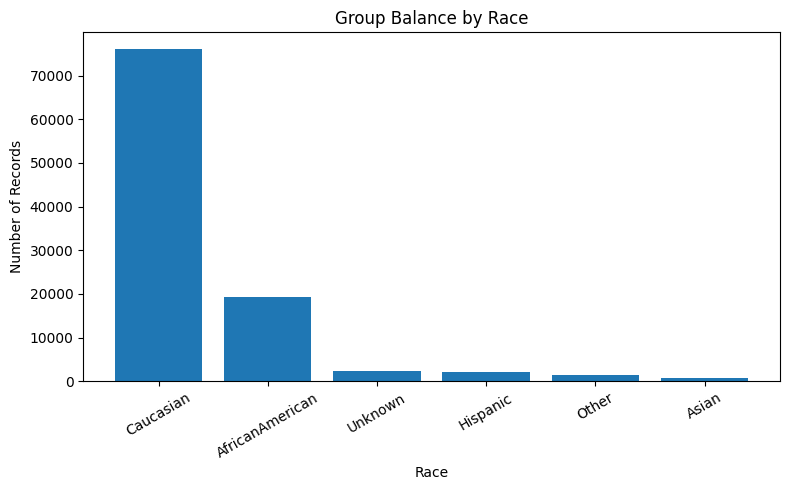

In [19]:
race_counts = df_clean['race'].value_counts()
print(race_counts)

plt.figure(figsize=(8, 5))
plt.bar(race_counts.index, race_counts.values)
plt.xlabel('Race')
plt.ylabel('Number of Records')
plt.title('Group Balance by Race')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 4. Exploratory / Diagnostic Charts

Three diagnostic charts were used to expose data problems:

1. **Missing Values by Column** (Section 3.1) shows which columns have missing data and how serious it is. Four columns have 70% or more missing values.
2. **Boxplot of Patient Visit Counts** (Section 3.3) shows the outliers in the visit variables and the heavily skewed distribution.
3. **Group Balance by Race** (Section 3.4) shows that the race groups are highly unbalanced, which is a potential source of bias.

## 5. PII and Bias Risks

**PII risks:** `encounter_id` and `patient_nbr` are identifiers. `patient_nbr` can link several encounters to the same patient. Combined with `age`, `race` and `gender`, records could potentially be re-identified. The identifiers are kept in `df_clean` only for data profiling (e.g. checking repeated patients), but they are removed from the dataset used for any further analysis or modelling, as shown below.

**Bias risks:**

- **Unbalanced race groups:** The race chart shows that Caucasian patients make up most of the records, while other groups (e.g. Asian, Hispanic) are very small. Results may not generalise to minority groups.
- **Age imbalance:** Most patients are older than 50, so younger patients are underrepresented.
- **Sampling bias:** The data comes only from US hospitals, so it may not represent patients in other countries.

**Handling:** Results should be evaluated separately for each demographic group, and stratified sampling or class weighting can be used if a model is trained on this data.

In [20]:
# Remove direct identifiers before any further analysis or modelling
df_model = df_clean.drop(columns=['encounter_id', 'patient_nbr'])

print("Identifier columns removed:", 'encounter_id' not in df_model.columns and 'patient_nbr' not in df_model.columns)
print("Analysis dataset shape:", df_model.shape)

Identifier columns removed: True
Analysis dataset shape: (101766, 44)


## 6. Conclusion

The dataset fits the scenario because it contains real data quality problems: missing values in several columns, `?` placeholders, an invalid gender value, untested lab results recorded as `None`, skewed count variables with many outliers, constant columns, and demographic imbalance. These issues were handled by dropping `weight` and `payer_code`, labelling untested lab results as `Not Measured`, filling other categorical gaps with `Unknown`, removing rows with a missing target, converting ID codes to categorical type, and dropping constant columns. Outliers were kept because they represent plausible patient records. No duplicate rows were found, and the before-vs-after table confirms that no missing or invalid values remain.

After cleaning, the dataset is fit for further analysis, such as studying hospital readmission. However, some limitations remain: patient weight information was lost, most patients have no glucose or A1C test results, the `Unknown` categories may hide patterns, and the unbalanced demographic groups may bias any conclusions.

## 7. Instructions to Run

1. Download `diabetic_data.csv` from the Kaggle link in Section 2 (the full file has 101,766 rows).
2. Open this notebook in Google Colab and upload `diabetic_data.csv` to the Colab session.
3. Make sure the file is located at `/content/diabetic_data.csv`.
4. Click **Runtime → Run all** to run the notebook from top to bottom.
5. Required libraries: pandas and matplotlib (both pre-installed in Colab).